# Indicators For Upcoming Economic "Crash"

[SOURCE: U.S. Bureau of Labor Statistics - Current Employment Statistics](https://download.bls.gov/pub/time.series/ce/ce.series)

In [1]:
from blsutils import BLSClient
from great_tables import GT, md, html
import matplotlib.pyplot as plt
import polars as pl
pl.Config.set_tbl_rows(24);

### Total # of People Employed from 2007 thru 2026 so that we can include 2008-2009 Recession Period, Pre-COVID, COVID, and recent data

Data through September 2026:

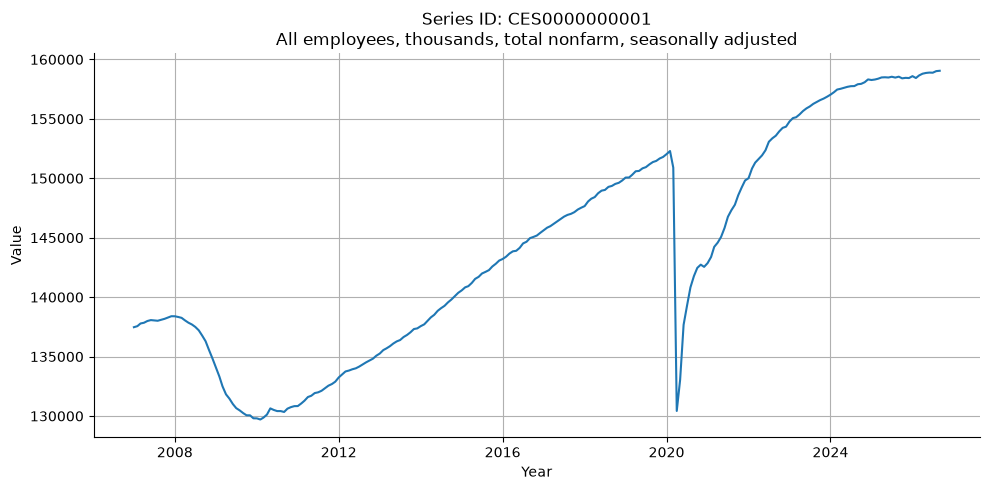

Last 13 recent months of data - values are in thousands


series_id,year_month,year,period,value,monthly_change
CES0000000001,2025-09-01,2025,M09,158548.0,76.0
CES0000000001,2025-10-01,2025,M10,158408.0,-140.0
CES0000000001,2025-11-01,2025,M11,158449.0,41.0
CES0000000001,2025-12-01,2025,M12,158432.0,-17.0
CES0000000001,2026-01-01,2026,M01,158592.0,160.0
CES0000000001,2026-02-01,2026,M02,158436.0,-156.0
CES0000000001,2026-03-01,2026,M03,158650.0,214.0
CES0000000001,2026-04-01,2026,M04,158798.0,148.0
CES0000000001,2026-05-01,2026,M05,158861.0,63.0
CES0000000001,2026-06-01,2026,M06,158892.0,31.0


In [2]:
with BLSClient() as client:
    df_all = client.fetch_df(series_id="CES0000000001", start_year=2007, end_year=2026)
    df_all = (
        df_all
        .sort(
            pl.col("year_month")
        )
        .with_columns(
            pl.col("value").diff().alias("monthly_change")
        )
    )
    client.plot_bls_series(df_all, "All employees, thousands, total nonfarm, seasonally adjusted")
    print("Last 13 recent months of data - values are in thousands")
    GT(df_all.tail(13)).cols_align(align="center").show()

## Now, let's look at difference or change in total employment numbers on a monthly basis ("monthly_change")

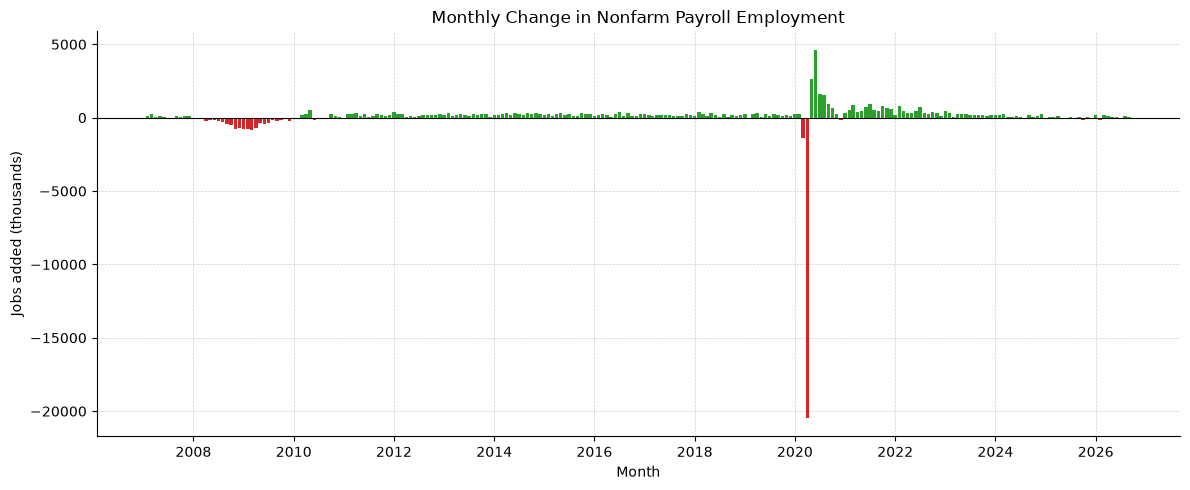

In [3]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Drop the first row (null diff) and pull out the columns
plot_df = df_all.drop_nulls("monthly_change")

x = plot_df["year_month"].to_list()
y = plot_df["monthly_change"].to_numpy()

fig, ax = plt.subplots(figsize=(12, 5))

# Optional: color gains and losses differently
colors = ["tab:green" if v >= 0 else "tab:red" for v in y]

ax.bar(x, y, width=25, color=colors)  # width is in days since x is a date axis

ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Monthly Change in Nonfarm Payroll Employment")
ax.set_xlabel("Month")
ax.set_ylabel("Jobs added (thousands)")

# Tidy up the date axis
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

# Remove top and right borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Show grid lines for major ticks on both axes, drawn behind the bars
ax.set_axisbelow(True)
ax.grid(True, which="major", axis="both", linestyle="--", linewidth=0.5, alpha=0.6)

plt.tight_layout()
plt.show()

#### From above, due to the extreme values, it is hard to visually compare.  So, let's compare "normal" employment periods which exclude extreme events.  So let's combine a data set containing only 2017 thru 2019 data with another data set contaning 2024 thru 2026 data.

In [4]:
df_2024_to_2026 = (
    df_all
    .filter(
        pl.col("year").is_in(["2024","2025","2026"])
    )
)

df_2017_to_2019 = (
    df_all
    .filter(
        pl.col("year").is_in(["2017","2018","2019"])
    )
)

df_joined_all = (
    pl.concat([df_2017_to_2019, df_2024_to_2026])
    .sort("year_month")
)

In [5]:
df_joined_all

series_id,year_month,year,period,value,monthly_change
str,date,str,str,f64,f64
"""CES0000000001""",2017-01-01,"""2017""","""M01""",145628.0,220.0
"""CES0000000001""",2017-02-01,"""2017""","""M02""",145846.0,218.0
"""CES0000000001""",2017-03-01,"""2017""","""M03""",145970.0,124.0
"""CES0000000001""",2017-04-01,"""2017""","""M04""",146175.0,205.0
"""CES0000000001""",2017-05-01,"""2017""","""M05""",146380.0,205.0
"""CES0000000001""",2017-06-01,"""2017""","""M06""",146583.0,203.0
"""CES0000000001""",2017-07-01,"""2017""","""M07""",146772.0,189.0
"""CES0000000001""",2017-08-01,"""2017""","""M08""",146919.0,147.0
"""CES0000000001""",2017-09-01,"""2017""","""M09""",147008.0,89.0


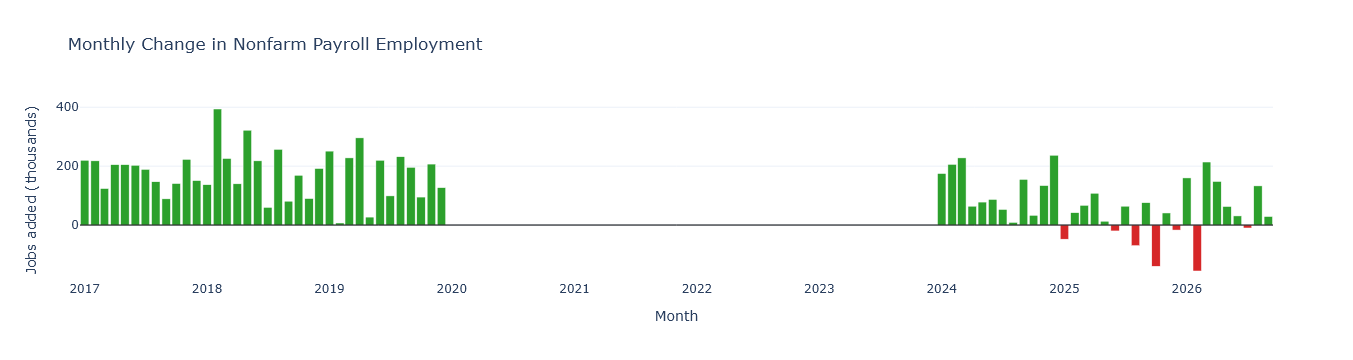

In [6]:
import plotly.graph_objects as go

# Drop the first row (null diff)
plot_df = df_joined_all.drop_nulls("monthly_change")

x = plot_df["year_month"].to_list()
y = plot_df["monthly_change"].to_list()

# Optional: color gains and losses differently
colors = ["#2ca02c" if v >= 0 else "#d62728" for v in y]

fig = go.Figure(
    go.Bar(
        x=x,
        y=y,
        marker_color=colors,
        hovertemplate="%{x|%b %Y}<br>%{y:,.0f}k jobs<extra></extra>",
    )
)

fig.update_layout(
    title="Monthly Change in Nonfarm Payroll Employment",
    xaxis_title="Month",
    yaxis_title="Jobs added (thousands)",
    template="plotly_white",
    bargap=0.1,
)

fig.add_hline(y=0, line_color="black", line_width=1)

fig.show()

**From above, we see it is now easier to visually compare.  There was a little bit of up-tick for beginning of 2026, but in recent months, jobs added are still low compared to pre-COVID.**

### Let's look at private sector employment

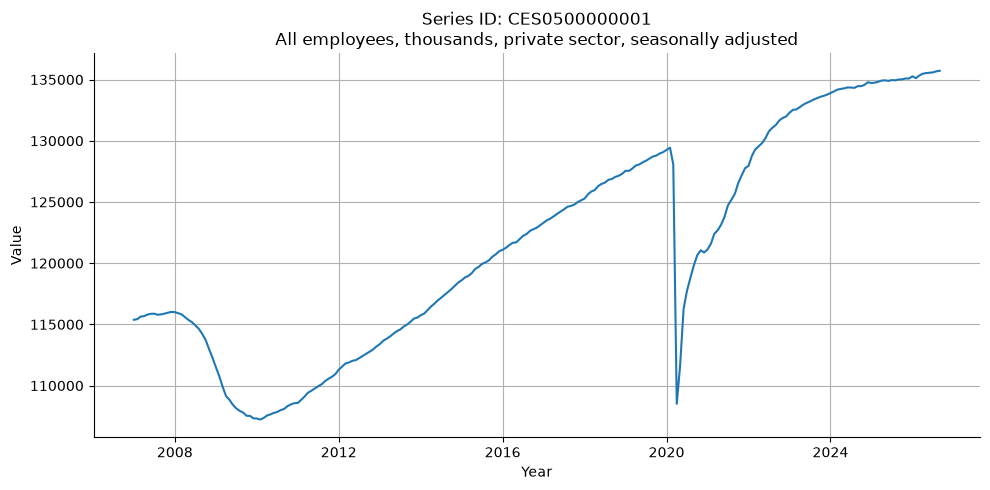

Last 13 recent months of data


series_id,year_month,year,period,value,monthly_change
CES0500000001,2025-09-01,2025,M09,135005.0,68.0
CES0500000001,2025-10-01,2025,M10,135018.0,13.0
CES0500000001,2025-11-01,2025,M11,135090.0,72.0
CES0500000001,2025-12-01,2025,M12,135083.0,-7.0
CES0500000001,2026-01-01,2026,M01,135263.0,180.0
CES0500000001,2026-02-01,2026,M02,135115.0,-148.0
CES0500000001,2026-03-01,2026,M03,135317.0,202.0
CES0500000001,2026-04-01,2026,M04,135467.0,150.0
CES0500000001,2026-05-01,2026,M05,135528.0,61.0
CES0500000001,2026-06-01,2026,M06,135554.0,26.0


In [7]:
with BLSClient() as client:
    df_private = client.fetch_df(series_id="CES0500000001", start_year=2007, end_year=2026)
    df_private = (
        df_private
        .sort(
            pl.col("year_month")
        )
        .with_columns(
            pl.col("value").diff().alias("monthly_change")
        )
    )
    client.plot_bls_series(df_private, "All employees, thousands, private sector, seasonally adjusted")
    print("Last 13 recent months of data")
    GT(df_private.tail(13)).cols_align(align="center").show()

**We recovered after the huge job losses in February 2026.  But recent months trend does not look favorable.**

In [8]:
df_2024_to_2026 = (
    df_private
    .filter(
        pl.col("year").is_in(["2024","2025","2026"])
    )
)

df_2017_to_2019 = (
    df_private
    .filter(
        pl.col("year").is_in(["2017","2018","2019"])
    )
)

df_joined_private = (
    pl.concat([df_2017_to_2019, df_2024_to_2026])
    .sort("year_month")
)

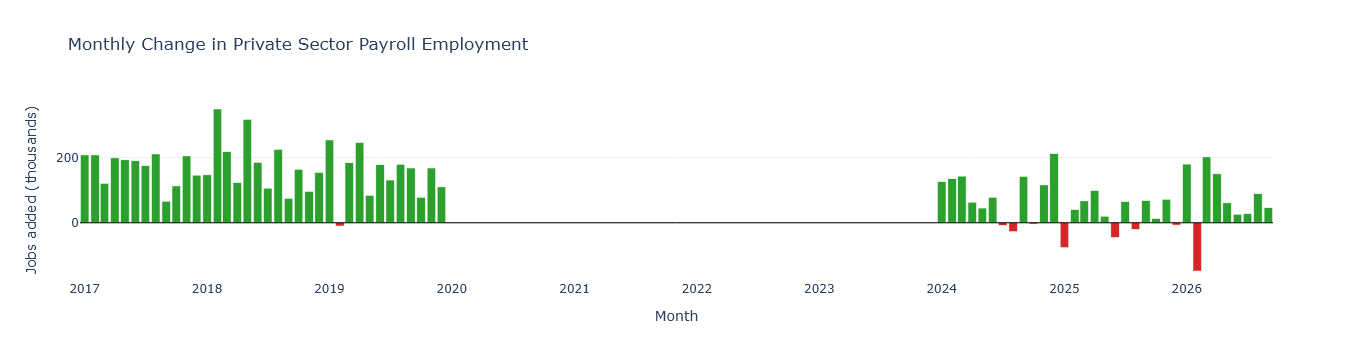

In [9]:
import plotly.graph_objects as go

# Drop the first row (null diff)
plot_df = df_joined_private.drop_nulls("monthly_change")

x = plot_df["year_month"].to_list()
y = plot_df["monthly_change"].to_list()

# Optional: color gains and losses differently
colors = ["#2ca02c" if v >= 0 else "#d62728" for v in y]

fig = go.Figure(
    go.Bar(
        x=x,
        y=y,
        marker_color=colors,
        hovertemplate="%{x|%b %Y}<br>%{y:,.0f}k jobs<extra></extra>",
    )
)

fig.update_layout(
    title="Monthly Change in Private Sector Payroll Employment",
    xaxis_title="Month",
    yaxis_title="Jobs added (thousands)",
    template="plotly_white",
    bargap=0.1,
)

fig.add_hline(y=0, line_color="black", line_width=1)

fig.show()

#### Average of monthly change from 2017 thru 2019 of all non-farm employment:

In [10]:
#| echo: true
#| code-fold: true
#| code-summary: "Show code"
(
    GT(
        df_all
        .filter(
            pl.col("year").is_in(["2017","2018","2019"])
        )
        .select(
            pl.col("monthly_change").mean().alias("avg_value")
        )
    )
    .fmt_number(columns="avg_value", decimals=2)
    .cols_align(align="center")
    .show()
)

avg_value
177.39


#### Average of monthly change from 2024 thru 2026 of all non-farm employment:

In [11]:
#| echo: true
#| code-fold: true
#| code-summary: "Show code"
(
    GT(
        df_all
        .filter(
            pl.col("year").is_in(["2024","2025","2026"])
        )
        .select(
            pl.col("monthly_change").mean().alias("avg_value")
        )
    )
    .fmt_number(columns="avg_value", decimals=2)
    .cols_align(align="center")
    .show()
)

avg_value
66.27


On average, during the few years before COVID, 177 thousand jobs were added.  From 2024 thru 2026, only 66 thousand jobs were added on average.

#### Average of monthly change from 2017 thru 2019 of all private sector employment:

In [12]:
#| echo: true
#| code-fold: true
#| code-summary: "Show code"
(
    GT(
        df_private
        .filter(
            pl.col("year").is_in(["2017","2018","2019"])
        )
        .select(
            pl.col("monthly_change").mean().alias("avg_value")
        )
    )
    .fmt_number(columns="avg_value", decimals=2)
    .cols_align(align="center")
    .show()
)

avg_value
165.67


#### Average of monthly change from 2024 thru 2026 of all private sector employment:

In [13]:
#| echo: true
#| code-fold: true
#| code-summary: "Show code"
(
    GT(
        df_private
        .filter(
            pl.col("year").is_in(["2024","2025","2026"])
        )
        .select(
            pl.col("monthly_change").mean().alias("avg_value")
        )
    )
    .fmt_number(columns="avg_value", decimals=2)
    .cols_align(align="center")
    .show()
)

avg_value
59.12


On average, during the few years before COVID, 166 thousand jobs were added.  From 2024 thru 2026, only 59 thousand jobs were added on average.

## Let's take population into account of employment-eligible persons (16 years old and over) using series ID "LNS12300000"

[SOURCE: U.S. Bureau of Labor Statistics - National Unemployment](https://download.bls.gov/pub/time.series/ln/ln.series)

Data through September 2026:

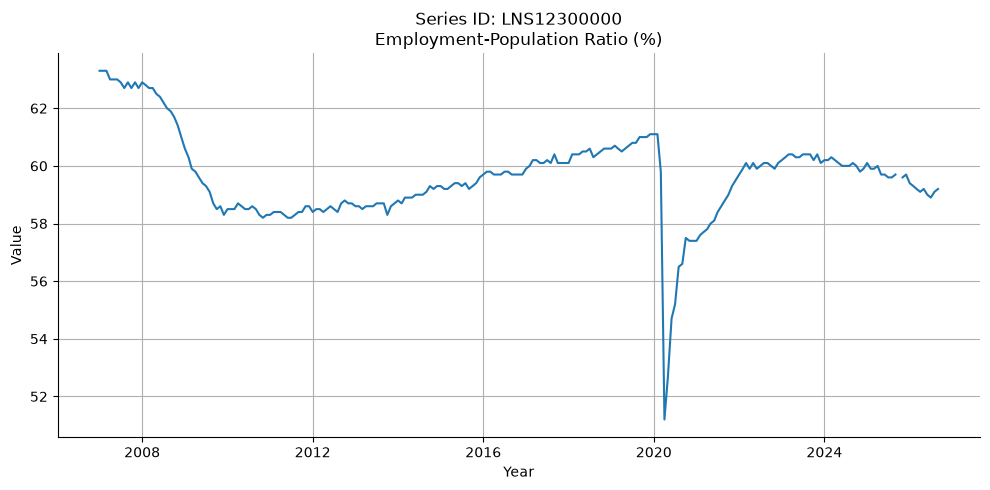

Last 5 recent months of data


series_id,year_month,year,period,value
LNS12300000,2026-05-01,2026,M05,59.2
LNS12300000,2026-06-01,2026,M06,59.0
LNS12300000,2026-07-01,2026,M07,58.9
LNS12300000,2026-08-01,2026,M08,59.1
LNS12300000,2026-09-01,2026,M09,59.2


In [14]:
with BLSClient() as client:
    df = client.fetch_df(series_id="LNS12300000", start_year=2007, end_year=2026)
    client.plot_bls_series(df, "Employment-Population Ratio (%)")
    print("Last 5 recent months of data")
    GT(df.tail()).show()

When taking into account population level, we are at a downward trend.  Pre-COVID, the trend was upwards.